# Ratings, the master scale and the through-the-cycle PD of a grade

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 to 04 of topic 01 (the engine, an artifact, a first test)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- read a rating agency's cohort table: the grades, the default state, the withdrawn ratings and the cohort size;
- turn one year's counts into a one-year PD by grade with the engine's cohort estimator, and say what happens to the withdrawn ratings;
- say why one year's PD is a point-in-time number and the average of many years is the through-the-cycle number the master scale needs;
- link the two with the one-factor (Merton-Vasicek) model, reading the credit-cycle factor each year implies;
- compare every recomputation with the committed artifact, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import estimators, ttc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C04 of Contraste, the S&P variant, as the product commits it. The source is ESMA's CEREP publication, the register where credit rating agencies report their ratings and their transitions (licence class `mirror-allowed`, attribution carried in the artifact: "Source: ESMA CEREP; tables transformed by Contraste"; https://registers.esma.europa.eu/cerep-publication/). The pipeline took the corporate, long-term ratings of the EU entity of S&P by category, put them on **seven performing grades** (AAA, AA, A, BBB, BB, B, CCC-C) plus **default**, and kept one table per annual **cohort**: the ratings alive on 1 January and where each stood on 31 December.

- **File read:** `data/derived/C04/sp.json`, keys `outputs.cohorts` (26 annual cohorts), `outputs.pd` (the one-year PD by cohort and grade under four definitions), `outputs.lra` (the long-run averages), `outputs.pooled` and `outputs.origination` (the pooled matrix and the cohort mix).
- **The definition matters.** CEREP states that "no deterministic definition of a default event has been set up", so each PD names its page. This notebook uses `d4`, the PD read off the transition page (the default column over the cohort less its withdrawals), the industry treatment. Notebook 10 of this topic shows how much the choice of page moves a PD.

The next cell loads the artifact and prints what it holds.

In [2]:
# Load the artifact (the notebook sits three folders below the repository root) and print what it holds
ROOT = Path("../../..").resolve()
sp = json.loads((ROOT / "data" / "derived" / "C04" / "sp.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades, states = out["grades"], out["states"]

print("agency:", out["agency"]["name"])
print("attribution:", out["attribution"])
print("baked by riskvalidation", sp["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("grades:", grades)
print("states:", states)
print("annual cohorts:", len(out["cohorts"]), "from", out["cohorts"][0]["label"], "to", out["cohorts"][-1]["label"])

agency: Standard & Poor's Credit Market Services Europe Limited
attribution: Source: ESMA CEREP; tables transformed by Contraste
baked by riskvalidation 1.0.1 | installed 1.0.1
grades: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C']
states: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C', 'D']
annual cohorts: 26 from 2000 to 2025


**One cohort.** Each cohort record holds, for the ratings alive at the start of the year, the `size` per grade, the `counts` of where they stood at the end (rows the grade at the start, columns the seven grades and default) and the `withdrawn` ratings: the ones the agency stopped rating during the year, whose end state is unknown. The next cell prints the 2000 cohort as a table and checks that the counts and the withdrawn ratings add up to the cohort size.

In [3]:
# Print the 2000 cohort: the counts by start grade (rows) and end state (columns), the withdrawn ratings and the size
c2000 = out["cohorts"][0]
counts = np.array(c2000["counts"], dtype=float)
withdrawn = np.array(c2000["withdrawn"], dtype=float)
size = np.array(c2000["size"], dtype=float)

print("cohort", c2000["label"], c2000["begin"], "to", c2000["end"])
print(f"{'':8s}" + "".join(f"{s:>7s}" for s in states) + f"{'withdrawn':>12s}{'size':>8s}")
for g, row, w, n in zip(grades, counts, withdrawn, size):
    print(f"{g:8s}" + "".join(f"{v:7.0f}" for v in row) + f"{w:12.0f}{n:8.0f}")
print("counts plus withdrawn equal the size in every grade:", bool(np.allclose(counts.sum(axis=1) + withdrawn, size)))

cohort 2000 2000-01-01 to 2000-12-31
            AAA     AA      A    BBB     BB      B  CCC-C      D   withdrawn    size
AAA         205     22      2      0      0      0      0      0          12     241
AA            5    776     67      4      0      0      0      0          71     923
A             0     55   1429    136      6      1      6      4         104    1741
BBB           1      6     65   1501     65      9      3      6          95    1751
BB            0      4      1     40    885     74      9      3          78    1094
B             0      5      3      5     47    791     47     53         119    1070
CCC-C         0      0      0      0      1     13     76     19          33     142
counts plus withdrawn equal the size in every grade: True


## Method

### Step 1: the one-year PD of a grade from one cohort

The cohort estimator of Anderson and Goodman (1957, equations 2.8 and 2.9) estimates the probability of moving from grade $i$ to state $j$ in one year as the share of the ratings that started in $i$ and ended in $j$:

$$\hat p_{ij} = \frac{N_{ij}}{N_i}$$

with $N_i$ the ratings that started in $i$ and are still observed at the end. The PD of grade $i$ is the entry of the default column, $\hat p_{i,D}$. The withdrawn ratings are not in $N_i$: the industry standard, "the method which has emerged as an industry standard" (Schuermann and Hanson, 2004, footnote 4), treats a withdrawal as non-informative and spreads it over the states in proportion to their values, which is the same as removing it and dividing by what remains. The engine's `cohort` takes a square table, so the next cell adds an empty default row (default is absorbing) and calls it with `treatment="exclude"`.

In [4]:
# One call to the engine's cohort estimator on the 2000 cohort, withdrawn ratings removed
square = np.vstack([counts, np.zeros(len(states))])   # an empty default row makes the table square
withdrawn8 = np.append(withdrawn, 0.0)
m_exclude = estimators.cohort(square, withdrawn8, treatment="exclude")
p_exclude = m_exclude["matrix"]

print("ratings in each start grade after removing the withdrawn:", m_exclude["row_sizes"][:7].astype(int))
print("share withdrawn:", np.round(m_exclude["withdrawn_share"][:7], 4))
print("rows sum to one:", bool(np.allclose(p_exclude.sum(axis=1), 1.0)))
print(f"{'':8s}" + "".join(f"{s:>9s}" for s in states))
for g, row in zip(grades, p_exclude[:7]):
    print(f"{g:8s}" + "".join(f"{v:9.4f}" for v in row))

ratings in each start grade after removing the withdrawn: [ 229  852 1637 1656 1016  951  109]
share withdrawn: [0.0498 0.0769 0.0597 0.0543 0.0713 0.1112 0.2324]
rows sum to one: True
              AAA       AA        A      BBB       BB        B    CCC-C        D
AAA        0.8952   0.0961   0.0087   0.0000   0.0000   0.0000   0.0000   0.0000
AA         0.0059   0.9108   0.0786   0.0047   0.0000   0.0000   0.0000   0.0000
A          0.0000   0.0336   0.8729   0.0831   0.0037   0.0006   0.0037   0.0024
BBB        0.0006   0.0036   0.0393   0.9064   0.0393   0.0054   0.0018   0.0036
BB         0.0000   0.0039   0.0010   0.0394   0.8711   0.0728   0.0089   0.0030
B          0.0000   0.0053   0.0032   0.0053   0.0494   0.8318   0.0494   0.0557
CCC-C      0.0000   0.0000   0.0000   0.0000   0.0092   0.1193   0.6972   0.1743


The default column of that matrix is the one-year PD by grade of the 2000 cohort. The artifact commits the same quantity for every cohort under `outputs.pd.d4`, so the next cell compares the recomputation with the committed row and prints the engine version that baked it (the artifact was baked with an older engine than the installed one, and a difference would be read against that).

In [5]:
# Compare the engine's default column with the committed PD of the 2000 cohort (definition d4)
pd_engine = p_exclude[:7, -1]
pd_committed = np.array(out["pd"]["d4"][0], dtype=float)
print("baked by riskvalidation", sp["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print(f"{'grade':8s}{'engine':>12s}{'committed':>14s}")
for g, a, b in zip(grades, pd_engine, pd_committed):
    print(f"{g:8s}{a:12.6f}{b:14.6f}")
print("equal to the committed PD:", bool(np.allclose(pd_engine, pd_committed, atol=1e-8)))

baked by riskvalidation 1.0.1 | installed 1.0.1
grade         engine     committed
AAA         0.000000      0.000000
AA          0.000000      0.000000
A           0.002443      0.002443
BBB         0.003623      0.003623
BB          0.002953      0.002953
B           0.055731      0.055731
CCC-C       0.174312      0.174312
equal to the committed PD: True


### Step 2: what the withdrawn ratings do to a PD

If a withdrawal is not informative, removing it is harmless. If a rating is withdrawn because the borrower is in trouble, removing it understates the PD. The engine's other treatment, `treatment="state"`, keeps the withdrawn ratings in the denominator as a ninth, absorbing state, which is how EBA/GL/2017/16 paragraph 76 keeps closed obligations in the sample. The next cell prints both PDs for the 2000 cohort. Notebook 10 measures the bias on rating paths whose truth is known.

In [6]:
# The same cohort with the withdrawn ratings kept as an absorbing state, beside the removal
m_state = estimators.cohort(square, withdrawn8, treatment="state")
pd_keep = m_state["matrix"][:7, len(states) - 1]
pd_keep_committed = np.array(out["pd"]["keep"][0], dtype=float)
print(f"{'grade':8s}{'removed (d4)':>20s}{'kept (keep)':>24s}{'ratio':>10s}")
for g, a, b in zip(grades, pd_engine, pd_keep):
    print(f"{g:8s}{a:20.6f}{b:24.6f}{(a / b if b > 0 else float('nan')):10.3f}")
print("equal to the committed keep column:", bool(np.allclose(pd_keep, pd_keep_committed, atol=1e-8)))

grade           removed (d4)             kept (keep)     ratio
AAA                 0.000000                0.000000       nan
AA                  0.000000                0.000000       nan
A                   0.002443                0.002298     1.064
BBB                 0.003623                0.003427     1.057
BB                  0.002953                0.002742     1.077
B                   0.055731                0.049533     1.125
CCC-C               0.174312                0.133803     1.303
equal to the committed keep column: True


### Step 3: from one year to the through-the-cycle PD

One year's PD is a point-in-time number: it moves with the economy. The master scale of a rating system needs the through-the-cycle (TTC) PD of each grade, the level the grade has over a whole cycle. The EBA guidelines (EBA/GL/2017/16, paragraph 84) define it as the long-run average of the one-year default rates, "the observed average of the one-year default rates" over the cohorts where the grade has ratings:

$$\mathrm{LRA}_i = \frac{1}{T_i} \sum_{t=1}^{T_i} \hat p_{i,D}(t)$$

The artifact holds the one-year PD of every cohort in `outputs.pd.d4` (26 rows, one per year, seven grades) and the average in `outputs.lra.d4.rate`. The next cell recomputes the average from the yearly rates, compares it with the committed one and prints, per grade, the lowest and highest year and the latest. It adds the pooled rate (all defaults over all ratings, so the large cohorts weigh more) with its Jeffreys interval from the artifact: the average of the yearly rates and the pooled rate answer slightly different questions.

In [7]:
# Average the yearly rates of each grade and compare with the committed long-run average (LRA)
yearly = np.array([[np.nan if v is None else v for v in row] for row in out["pd"]["d4"]], dtype=float)   # 26 cohorts x 7 grades
years = [c["label"] for c in out["cohorts"]]
lra_here = np.nanmean(yearly, axis=0)
lra_committed = np.array(out["lra"]["d4"]["rate"], dtype=float)
pooled_rate = np.array(out["lra"]["d4"]["pooled_rate"], dtype=float)
jeffreys_low = np.array(out["lra"]["d4"]["jeffreys"]["lower"], dtype=float)
jeffreys_high = np.array(out["lra"]["d4"]["jeffreys"]["upper"], dtype=float)

print("baked by riskvalidation", sp["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print(f"{'grade':8s}{'LRA':>10s}{'committed':>12s}{'lowest year':>16s}{'highest year':>16s}{'latest':>10s}{'pooled rate':>16s}{'95% interval of the pooled rate (Jeffreys)':>48s}")
for g in range(7):
    lo, hi = int(np.nanargmin(yearly[:, g])), int(np.nanargmax(yearly[:, g]))
    interval = f"{jeffreys_low[g]:.5f} to {jeffreys_high[g]:.5f}"
    print(f"{grades[g]:8s}{lra_here[g]:10.5f}{lra_committed[g]:12.5f}{years[lo] + ' ' + format(yearly[lo, g], '.4f'):>16s}{years[hi] + ' ' + format(yearly[hi, g], '.4f'):>16s}{yearly[-1, g]:10.4f}{pooled_rate[g]:16.5f}{interval:>48s}")
print("the average equals the committed LRA:", bool(np.allclose(lra_here, lra_committed, atol=1e-8)))
print("the master scale rises with the grade:", bool(np.all(np.diff(lra_here) > 0)))

baked by riskvalidation 1.0.1 | installed 1.0.1
grade          LRA   committed     lowest year    highest year    latest     pooled rate      95% interval of the pooled rate (Jeffreys)
AAA        0.00000     0.00000     2000 0.0000     2000 0.0000    0.0000         0.00000                              0.00000 to 0.00132
AA         0.00005     0.00005     2000 0.0000     2008 0.0013    0.0000         0.00005                              0.00001 to 0.00023
A          0.00030     0.00030     2003 0.0000     2001 0.0025    0.0000         0.00029                              0.00016 to 0.00048
BBB        0.00079     0.00079     2003 0.0000     2002 0.0053    0.0000         0.00082                              0.00058 to 0.00112
BB         0.00336     0.00336     2006 0.0000     2001 0.0216    0.0000         0.00346                              0.00279 to 0.00425
B          0.01330     0.01330     2007 0.0000     2000 0.0557    0.0054         0.01173                              0.01059 to 0

The figure draws the yearly PD of the three speculative grades against their long-run average. The yearly rate swings around its average (note the different vertical scales); the table above names the highest and the lowest year of each grade. The average is the number a master scale uses; the yearly rate is what a point-in-time system reports.

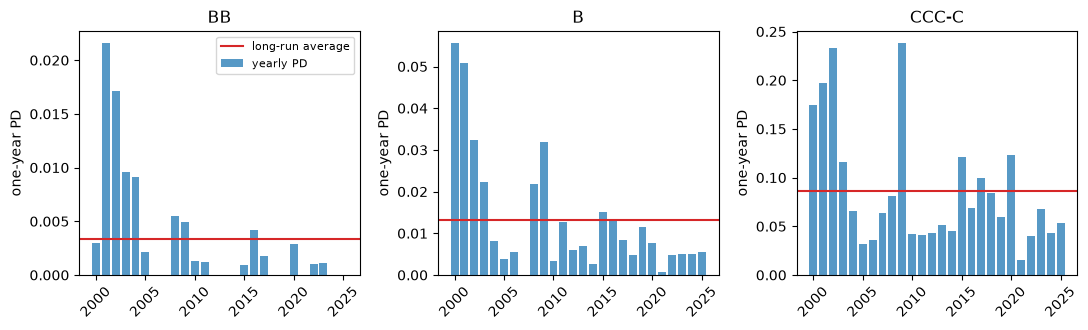

In [8]:
# Draw the yearly one-year PD of BB, B and CCC-C with the long-run average as a line
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, g in zip(axes, (4, 5, 6)):
    ax.bar(range(len(years)), yearly[:, g], color="tab:blue", alpha=0.75, label="yearly PD")
    ax.axhline(lra_here[g], color="tab:red", label="long-run average")
    ax.set_xticks(range(0, len(years), 5))
    ax.set_xticklabels(years[::5], rotation=45)
    ax.set_title(grades[g])
    ax.set_ylabel("one-year PD")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

### Step 4: the link between the two, the one-factor model

Why does the yearly rate swing around the average? The Merton-Vasicek model gives each obligor an asset return $A = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon$, with a systematic factor $Z$ shared by all obligors (the economy) and an idiosyncratic one $\varepsilon$; the obligor defaults when $A$ falls below $\Phi^{-1}(p)$, where $p$ is the through-the-cycle PD. Given the state of the economy $Z = z$ the default probability, the point-in-time PD, is

$$p_{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(p) - \sqrt{\rho}\, z}{\sqrt{1-\rho}}\right)$$

(Vasicek, 2002). A low $z$ is a bad year. Inverting the formula, an observed yearly default rate $\mathrm{DR}_t$ implies the factor $z_t = \bigl(\Phi^{-1}(p) - \sqrt{1-\rho}\,\Phi^{-1}(\mathrm{DR}_t)\bigr)/\sqrt{\rho}$: the credit-cycle index of that year. The engine has both directions, `vasicek.conditional_pd` and `vasicek.implied_factor`. The asset correlation $\rho$ is an assumption: the next cell takes the Basel III corporate value that `irb.correlation` gives at the grade's TTC PD (it is the IRB formula's value, not an estimate from these data). Grade B is used because it has a default in most years; a year with a rate of exactly zero implies no finite factor and is skipped.

In [9]:
# Read the credit-cycle factor each year implies for grade B, then go back to the PD to check the round trip
g = 5                                                   # grade B
ttc_pd = float(lra_here[g])
rho = irb.correlation("corporate", ttc_pd)              # Basel III corporate asset correlation at the TTC PD
rate = yearly[:, g]
usable = np.isfinite(rate) & (rate > 0)

z = vasicek.implied_factor(rate[usable], ttc_pd, rho)
back = vasicek.conditional_pd(ttc_pd, rho, z)

print("TTC PD of B:", round(ttc_pd, 5), "| rho:", round(rho, 4))
print("years with a default rate above zero:", int(usable.sum()), "of", len(years))
print("round trip equals the observed rate:", bool(np.allclose(back, rate[usable])))
order = np.argsort(z)
used_years = [yr for yr, ok in zip(years, usable) if ok]
print("five worst years (lowest factor):", [(used_years[k], round(float(z[k]), 2)) for k in order[:5]])
print("five best years (highest factor):", [(used_years[k], round(float(z[k]), 2)) for k in order[::-1][:5]])
print("mean of the factor over the years used (standard normal in theory):", round(float(z.mean()), 3))

TTC PD of B: 0.0133 | rho: 0.1817
years with a default rate above zero: 25 of 26
round trip equals the observed rate: True
five worst years (lowest factor): [('2000', -1.82), ('2001', -1.73), ('2002', -1.28), ('2009', -1.27), ('2003', -0.94)]
five best years (highest factor): [('2021', 1.62), ('2014', 0.7), ('2010', 0.54), ('2005', 0.47), ('2018', 0.31)]
mean of the factor over the years used (standard normal in theory): -0.209


The figure shows the factor the model reads from grade B's default rate each year. The bars below zero are the years worse than the average cycle.

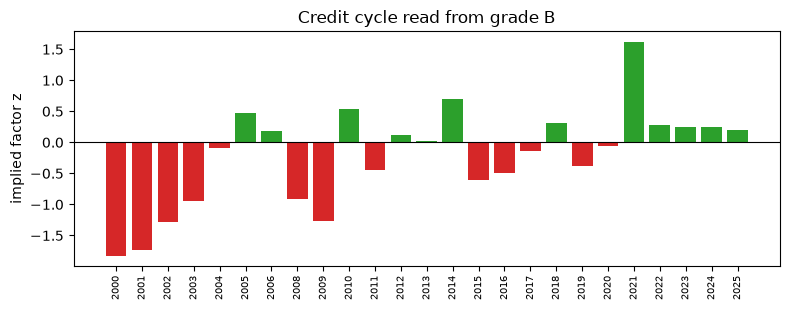

In [10]:
# Draw the credit-cycle factor implied by the yearly default rate of grade B
fig, ax = plt.subplots(figsize=(8, 3.2))
colors = ["tab:red" if v < 0 else "tab:green" for v in z]
ax.bar(range(len(z)), z, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(len(z)))
ax.set_xticklabels(used_years, rotation=90, fontsize=7)
ax.set_ylabel("implied factor z")
ax.set_title("Credit cycle read from grade B")
fig.tight_layout()
plt.show()

### Step 5: the TTC portfolio of the pooled matrix

A matrix gives the TTC PD a second way. If the portfolio is propagated year after year with the pooled one-year matrix, its defaulted part written off and re-originated with the observed cohort mix, it converges to one portfolio, the through-the-cycle portfolio $W_{\mathrm{ttc}}$ of Engelmann (2024), whose default rate is $W_{\mathrm{ttc}}' T V_w$ (with $V_w$ the default column). The engine's `ttc_portfolio` iterates that map. The artifact commits the pooled matrix (`outputs.pooled.matrix`, withdrawn ratings removed), the origination mix (`outputs.origination`) and the default rate of the result (`impact.ttc_default_rate`) beside the default rate of the latest cohort's mix. The next cell recomputes it. Notebook 07 develops the formula and its drift.

In [11]:
# Iterate the TTC portfolio of the pooled matrix with the observed cohort mix and compare with the committed rates
pooled = np.array(out["pooled"]["matrix"], dtype=float)
origination = np.array(out["origination"], dtype=float)
result = ttc.ttc_portfolio(pooled, origination)

print("iterations:", result["iterations"], "| converged:", result["converged"])
print(f"{'':8s}" + "".join(f"{s:>8s}" for s in states))
print(f"{'TTC portfolio':8s}" + "".join(f"{v:8.4f}" for v in result["portfolio"]))
print("default rate of the TTC portfolio:", round(result["default_rate"], 6), "| committed:", round(sp["impact"]["ttc_default_rate"]["value"], 6))
print("default rate of the latest cohort's mix:", round(sp["impact"]["latest_default_rate"]["value"], 6))
print("equal to the committed rate:", bool(np.isclose(result["default_rate"], sp["impact"]["ttc_default_rate"]["value"], atol=1e-8)))

iterations: 697 | converged: True
             AAA      AA       A     BBB      BB       B   CCC-C       D
TTC portfolio  0.0013  0.0519  0.2865  0.3039  0.1541  0.1608  0.0415  0.0000
default rate of the TTC portfolio: 0.006097 | committed: 0.006097
default rate of the latest cohort's mix: 0.0077
equal to the committed rate: True


## Results

- **One year, one cohort.** The engine's cohort estimator turns the 2000 counts into a one-year PD by grade and equals the committed `outputs.pd.d4` row to 1e-8 (the artifact was baked with riskvalidation 0.4.3, the notebook runs 0.8.1, and nothing moved). In that cohort grade B had a PD of 5.57% and CCC-C of 17.43%.
- **The withdrawn ratings move the PD.** Removing them is the industry treatment; keeping them as an absorbing state lowers B's 2000 PD to 4.95% and CCC-C's to 13.38%, because 11.1% of the B ratings and 23.2% of the CCC-C ratings were withdrawn within the year. Whether a withdrawal says nothing about the borrower is an assumption; notebook 10 tests it.
- **One year is not a master-scale PD.** B's yearly PD runs from 0 (first reached in 2007) to 5.57% (2000) around a long-run average of 1.33%; CCC-C's from 1.58% (2021) to 23.86% (2009) around 8.61%. The seven averages rise with the grade (0 for AAA, 0.005% for AA, 0.030% for A, 0.079% for BBB, 0.34% for BB, 1.33% for B, 8.61% for CCC-C) and equal the committed `outputs.lra.d4.rate`.
- **The cycle is readable.** With the Basel III corporate correlation (an assumption, 0.18 at B's PD), grade B's yearly default rate implies a credit-cycle factor whose lowest years are 2000, 2001, 2002, 2009 and 2003. The mean of the 25 usable factors is -0.21, not the 0 of a standard normal: 26 years from 2000 are a small sample of a cycle, and the correlation is assumed, so read the factor as an index, not a measurement.
- **A second route to the same level.** Iterating the pooled matrix with the observed cohort mix gives a TTC portfolio whose default rate is 0.61%, equal to the committed value, against 0.77% for the latest cohort's mix.

What this notebook does not show: how the cohort, duration and Aalen-Johansen estimators differ (notebook 02), whether a one-year matrix describes a cohort over several years (notebook 04), or how a PD becomes capital (notebook 07).

## Summary

- A rating agency's cohort table gives, per grade, where the ratings stood a year later; the share that ended in default, over the ratings still observed, is the one-year PD of the grade.
- Withdrawn ratings are removed by the industry treatment and kept by the EBA paragraph 76 reading; the two differ most in the weakest grades.
- A master scale needs the through-the-cycle PD, the average of many yearly rates; the one-factor model links the two and reads a credit-cycle factor from each year.
- Every recomputation is compared with the committed artifact only after naming the engine version that baked it.

**What to try next.** Change the grade in Step 4 from B to BB and compare the worst years; then read notebook 02 and continue with the duration estimator.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions, with the help file ESMA65-8-10634. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 2.8 and 2.9. https://doi.org/10.1214/aoms/1177707039
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, footnote 4. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, paragraphs 76, 84 and 86.
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892.